# DEL 1 :Grundlägande analys och statistik

## 1. Import och datainläsning

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [177]:
df = pd.read_csv("../data/health_study_dataset (1).csv")

## 2. Översikt över datasetet

### 2.1. Datasetets struktur och datatyper

In [178]:
display(df.head(3))
display(df.tail(3))

print(f"Datasetet  --  -  Antal rader: {df.shape[0]}  --  Antal kolumner: {df.shape[1]}")

print(f"\n{"Kolumnamn": <20} Datatype:")
for column in df.columns:
    print(f" - {column: <15} : {df[column].dtype}")

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
797,798,60,F,175.0,49.7,146.5,5.57,No,0
798,799,50,F,172.6,55.3,155.0,3.58,No,0
799,800,50,M,189.2,79.4,139.7,5.62,No,0


Datasetet  --  -  Antal rader: 800  --  Antal kolumner: 9

Kolumnamn            Datatype:
 - id              : int64
 - age             : int64
 - sex             : str
 - height          : float64
 - weight          : float64
 - systolic_bp     : float64
 - cholesterol     : float64
 - smoker          : str
 - disease         : int64


### 2.2. Datavalidering och datarensning

In [179]:
expected_values = ({df.columns[0]: df["id"].is_unique,
                    df.columns[2]: df["sex"].isin(["M", "F"]).all(),
                    df.columns[7]: df["smoker"].isin(["No", "Yes"]).all(),
                    df.columns[8]: df["disease"].isin([0, 1]).all(),
                    })
display(pd.DataFrame(expected_values, index=["Validering"]).replace({True: "Korrekt", False: "Fel"}))

,id,sex,smoker,disease
Validering,Korrekt,Korrekt,Korrekt,Korrekt


### 2.2.1. Saknade värden i datasetet

In [180]:

display(df.isna().sum().to_frame(name="Saknade värden").T)

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
Saknade värden,0,0,0,0,0,0,0,0,0


### 2.2.2. Validation of datatyper i datasetet

In [181]:
expected_types = {
    "id": "int", 
    "age": "int", 
    "sex": "str", 
    "height": "float",
    "weight": "float",
    "systolic_bp": "float",
    "cholesterol": "float",
    "smoker": "str",
    "disease": "int"
    }


correct_columns = []
incorrect_columns = []


for column in df.columns:
    expected_type = expected_types[column]
    passed = True
    
    for value in df[column]:
        actual_type = type(value).__name__
        if actual_type != expected_type:
            passed = False
    if passed:
        correct_columns.append(column)
    else:
        incorrect_columns.append(column)

result = {column: "Korrekt" if column in correct_columns else "Fel" for column in df.columns}

display(pd.DataFrame(result, index=["Datatyp validering"]))

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
Datatyp validering,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt


## 3. Beskrivande analys för datasetet

### 3.1. Beskrivande statistik för datasetet

In [182]:
analysis_value = df[["age", "height", "weight", "systolic_bp", "cholesterol"]].agg(["mean", "median", "min", "max"])

display(analysis_value.round(2))

,age,height,weight,systolic_bp,cholesterol
mean,49.43,171.85,73.41,149.18,4.93
median,50.00,171.35,73.20,149.40,4.97
min,18.00,144.40,33.70,106.80,2.50
max,90.00,200.40,114.40,185.90,7.88


### 3.2. Visualisering

### 3.2.1 Histogram över systoliskt blodtryck

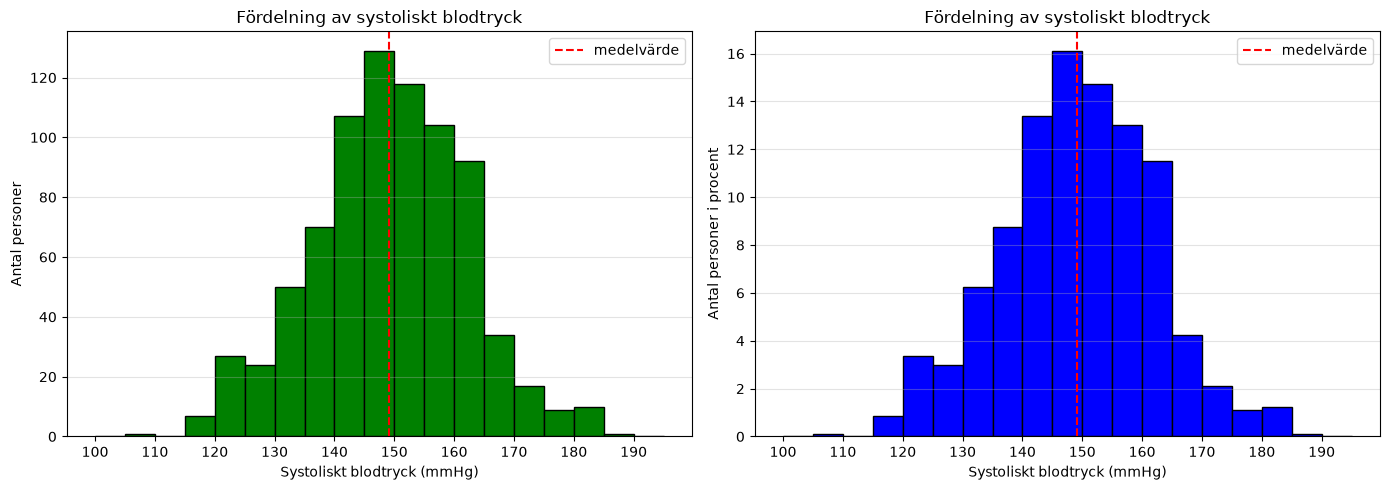

In [183]:

fig, ax = plt.subplots(1,2, figsize=(14,5))

ax[0].hist(df["systolic_bp"], bins=np.arange(100, 200, 5), edgecolor="black", color="green")
ax[0].set_xticks(np.arange(100, 200, 10))
ax[0].set_title("Fördelning av systoliskt blodtryck")
ax[0].set_xlabel("Systoliskt blodtryck (mmHg)")
ax[0].set_ylabel("Antal personer")

ax[0].axvline(df["systolic_bp"].mean(),
            color="red",
            linestyle="--", 
            label="medelvärde")
ax[0].grid(axis="y", alpha=0.35)
ax[0].legend()

ax[1].hist(df["systolic_bp"], weights=np.ones_like(df["systolic_bp"])*100 / len(df["systolic_bp"]), bins=np.arange(100, 200, 5), edgecolor="black", color="blue")
ax[1].set_xticks(np.arange(100, 200, 10))
ax[1].set_title("Fördelning av systoliskt blodtryck")
ax[1].set_xlabel("Systoliskt blodtryck (mmHg)")
ax[1].set_ylabel("Antal personer i procent")

ax[1].axvline(df["systolic_bp"].mean(),
            color="red",
            linestyle="--", 
            label="medelvärde")
ax[1].grid(axis="y", alpha=0.35)
ax[1].legend()

plt.tight_layout()
plt.show()


## boxplot sex bp

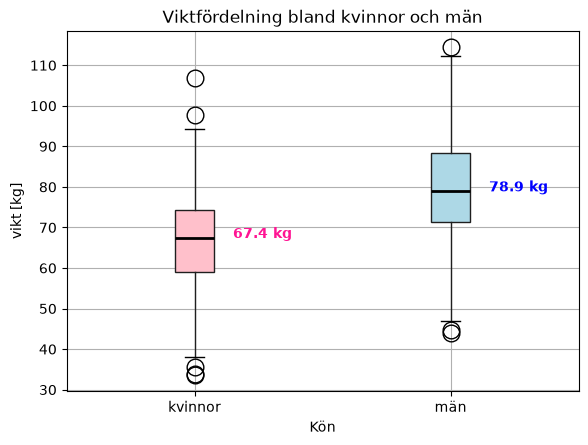

In [ ]:
median_kvinnor = df[df["sex"] == "F"]["weight"].median()
median_man = df[df["sex"] == "M"]["weight"].median()

ax = df.boxplot(column="weight", 
           by="sex",
           patch_artist=True,
           flierprops={
               "marker": "o",
               "markersize":12,
               "label":"avvikande"
           },
           medianprops={
                "linewidth":2,
                "color":"black",
                "label":"median"
           }
           )
ax.patches[0].set_facecolor("pink")
ax.patches[1].set_facecolor("lightblue")

ax.text(1.15, median_kvinnor, f"{median_kvinnor:.1f} kg",
        color="deeppink",
        fontweight="bold")

ax.text(2.15, median_man, f"{median_man:.1f} kg",
        color="blue",
        fontweight="bold")

plt.title("Viktfördelning bland kvinnor och män")
plt.suptitle("")

plt.xlabel("Kön")
plt.ylabel("vikt [kg]")

plt.xticks([1,2], ["kvinnor", "män"])

plt.show()

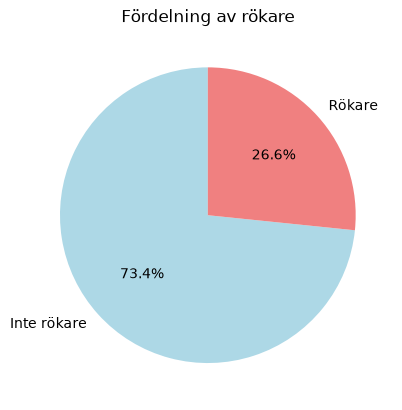

In [185]:
plt.pie(df["smoker"].value_counts(), labels=["Inte rökare", "Rökare"], autopct="%1.1f%%", startangle=90, colors=["lightblue", "lightcoral"])
plt.title("Fördelning av rökare")
plt.show()

In [186]:
grouped = df.groupby("sex")

data ={}

for sex, groupp in grouped:
    total = len(groupp)

    smoker_count = groupp["smoker"].value_counts()

    data[sex] = smoker_count


procent_smokers = pd.DataFrame(data).T
data_procent ={}
for sex, groupp in grouped:
    total = len(groupp)

    smoker_count = groupp["smoker"].value_counts()*100/total 
    
    data_procent[sex] = smoker_count


procent_smokers = pd.DataFrame(data_procent).T
counted_smokers = pd.DataFrame(data).T

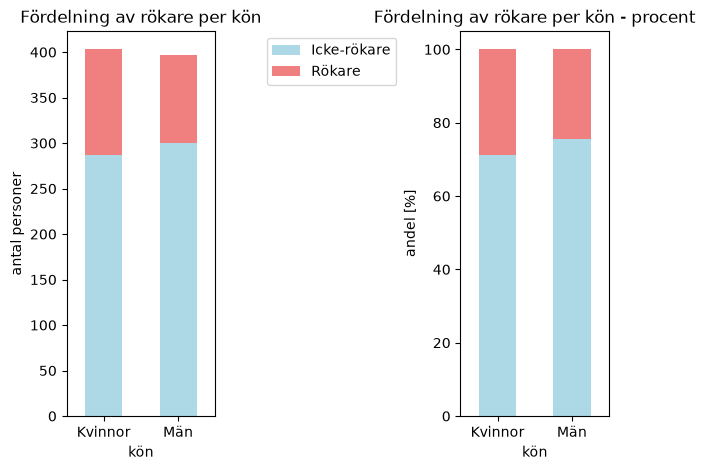

In [187]:

fig, ax= plt.subplots(1, 2, figsize=(7, 5))
counted_smokers.plot(kind="bar", stacked=True, color=["lightblue", "lightcoral"], ax=ax[0])


procent_smokers.plot(kind="bar", stacked=True, color=["lightblue", "lightcoral"], ax=ax[1])

ax[0].set_title("Fördelning av rökare per kön")
ax[0].set_xlabel("kön")
ax[0].set_ylabel("antal personer")
ax[0].set_xticklabels(["Kvinnor", "Män"], rotation=0)

ax[1].set_title("Fördelning av rökare per kön - procent")
ax[1].set_xlabel("kön")
ax[1].set_ylabel("andel [%]")
ax[1].set_xticklabels(["Kvinnor", "Män"], rotation=0)
ax[1].set_ylim(0, 105)

ax[0].legend(["Icke-rökare", "Rökare"], loc="upper left", bbox_to_anchor=(1.3,1))
ax[1].get_legend().remove()

plt.subplots_adjust(wspace=1.65)

plt.show()

## 4. Simulering kopplad till caset

### 4.1 Andelen personer i datasetet som har sjukdom

 I analysen antar vi att:
 disease = 0 betyder att personen har inte sjukdom och disease = 1 betyder att personen har sjukdomen.

In [188]:
disease_rate = df["disease"].mean()

print(f"Andel personer med sjukdom:  {disease_rate:4%}")

Andel personer med sjukdom:  5.875000%


Andel personer med sjukdom 5,875%.

### 4.2 ny grupp med 1000 slumpade personer

In [189]:
np.random.seed(42)

simulated_objects = np.random.choice([0, 1], size=1000, p=[1-disease_rate, disease_rate])

simulated_group = simulated_objects.mean()

print(f"Simulerad andel med sjuktom: {simulated_group:.4%}")

Simulerad andel med sjuktom: 5.6000%


### 4.3 Jämföra

In [190]:
print(f" Andel personer med sjukdom:  {disease_rate:.4%}\n Simulerad andel med sjuktom: {simulated_group:.4%}")
print(f" Skylnad mellan simulerade grupp och info från datasetet:  {simulated_group - disease_rate:.4%}")

 Andel personer med sjukdom:  5.8750%
 Simulerad andel med sjuktom: 5.6000%
 Skylnad mellan simulerade grupp och info från datasetet:  -0.2750%


## 5. Konfidensintervall - normalapproximation

In [191]:
mean_sys_bp = df["systolic_bp"].mean()
print(mean_sys_bp)

149.178625


#### 5.1 Standartni avvikelse

In [192]:
sd_sys_bp= df["systolic_bp"].std()
print (sd_sys_bp)

12.793360316766597


#### 5.2 Standart fel

In [193]:
count_p = df["systolic_bp"].count()
print(count_p)
se_sys_bp =  sd_sys_bp / (count_p**0.5)
print(se_sys_bp)

800
0.4523135917074269


#### 5.3 Konfidensintervall - felmarginal, gränser

In [194]:
margin_error = 1.96 * se_sys_bp
print(margin_error)

lower_bound = mean_sys_bp - margin_error
upper_bound = mean_sys_bp + margin_error
print(f"95% konfidensintervall ligger mellan {lower_bound:.4f} mmHg och {upper_bound:.4f} mmHg")

0.8865346397465568
95% konfidensintervall ligger mellan 148.2921 mmHg och 150.0652 mmHg


## 5. Konfidensintervall boostrap

In [203]:
nn = df["systolic_bp"]
np.random.seed(42)
a = 50000

bootstrap_means = []

for i in range (a):
    sample = np.random.choice(nn, count_p, replace = True)
    sample_mean = sample.mean()
    bootstrap_means.append(sample_mean)

print(len(bootstrap_means))
display(bootstrap_means[:5])


50000


[np.float64(148.545625),
 np.float64(147.935125),
 np.float64(148.327),
 np.float64(148.92762499999998),
 np.float64(149.148)]

### 5.2 stability i bootstrapresultatet

In [204]:

start = None
lower_bounds = []
upper_bounds = []
count_bootstrap = []
n = 500
max_interations = len(bootstrap_means)
while n < max_interations :
    count_bootstrap.append(n)
    n = n+1000

count_bootstrap.append(max_interations)

changes = []

for n in count_bootstrap:
    lower = np.percentile(bootstrap_means[:n], 2.5)
    upper = np.percentile(bootstrap_means[:n], 97.5)

    lower_bounds.append(lower)
    upper_bounds.append(upper)
    if start is not None:
        change = max(abs(lower - start[0]),
                     abs(upper - start[1]))
        changes.append(change)
        
        
        if 0.005<change<0.15:
            print(f"{n}: {change:.2f}")
        

    start =(lower, upper)
   

1500: 0.05
2500: 0.02
3500: 0.02
4500: 0.02
6500: 0.01
8500: 0.01
10500: 0.01
11500: 0.01
18500: 0.01


### 5.1 boostrap - gränser

In [205]:
bootstrap_lower_bound = np.percentile(bootstrap_means, 2.5)
bootstrap_upper_bound = np.percentile(bootstrap_means, 97.5)
print(f"95% konfidensintervall ligger lellan {bootstrap_lower_bound:.4f} mmHg och {bootstrap_upper_bound:.4f} mmHg")

95% konfidensintervall ligger lellan 148.2982 mmHg och 150.0629 mmHg


### 5.3 slutsats

In [206]:

print(f"Konfidensinterval:  95% konfidensintervall ligger mellan {lower_bound:.4f} mmHg och {upper_bound:.4f} mmHg")
print(f"Bootstrap:          95% konfidensintervall ligger lellan {bootstrap_lower_bound:.4f} mmHg och {bootstrap_upper_bound:.4f} mmHg")


Konfidensinterval:  95% konfidensintervall ligger mellan 148.2921 mmHg och 150.0652 mmHg
Bootstrap:          95% konfidensintervall ligger lellan 148.2982 mmHg och 150.0629 mmHg


### förklarning

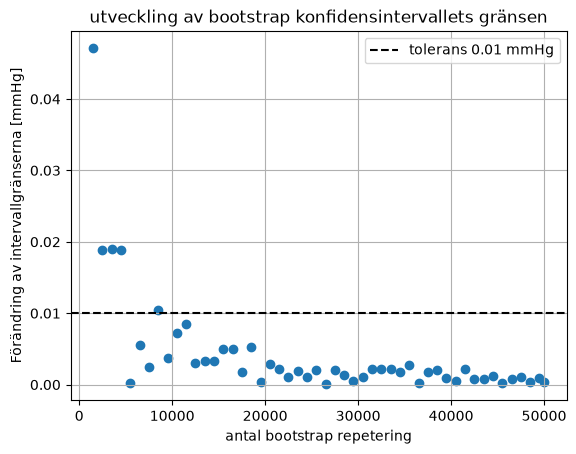

In [207]:
plt.scatter(count_bootstrap[1:], changes)

plt.axhline(0.01, color="black", linestyle="--", label="tolerans 0.01 mmHg")

plt.xlabel("antal bootstrap repetering")
plt.ylabel("Förändring av intervallgränserna [mmHg]")
plt.title("utveckling av bootstrap konfidensintervallets gränsen")

plt.legend()
plt.grid(True)

plt.show()

## 6. Hypotesprövning

### Påstående :" Rökare har högre medelblodtryck än icke-rökare."

### 6.1 formulera hypoteser

H0: Rökare har inte högre medelblodtryck än icke-rökare. 
H1: Rökare har högre medelblodtryck än icke-rökare.

### 6.2 signifikansnivå

In [215]:
alpha = 0.05

### 6.3 Data

In [216]:
smoker = df[df["smoker"] == "Yes"]["systolic_bp"].dropna()
no_smoker = df[df["smoker"] == "No"]["systolic_bp"].dropna()

print("Rökare:" ,  smoker.mean())
print("Icke_rökare:" ,  no_smoker.mean())

Rökare: 149.524882629108
Icke_rökare: 149.05298126064736


### 6.4 T-test p-värde

Welch

In [222]:
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(
    smoker, no_smoker, equal_var=False, alternative="greater"
)

print("T-statistik:", t_stat)
print("P-värde:", p_value)

if p_value < alpha:
    print("bb")
else:
    print("ss")

T-statistik: 0.4503433193393224
P-värde: 0.32636693716994986
ss


Student

In [221]:
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(
    smoker, no_smoker, equal_var=True, alternative="greater"
)

print("T-statistik:", t_stat)
print("P-värde:", p_value)

if p_value < alpha:
    print("bb")
else:
    print("ss")

T-statistik: 0.4609102005307389
P-värde: 0.32249430954835984
ss


power